<div align="center">

# **TUGAS 2 EKSEKUSI PROMPT**
## **KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**

### Disusun Oleh

| Nama | NIM |
|---|---|
| **HARDIS HERO PRATAMA** | **H061241068** |

**DEPARTEMEN GEOFISIKA**  
**FAKULTAS MIPA**  
**UNIVERSITAS HASANUDDIN**

</div>

---

# RTCIKOQV — Eksekusi Prompt AI untuk 5 Studi Kasus Geofisika

Notebook ini mengembangkan lima prompt dari tugas sebelumnya menjadi contoh eksekusi yang memuat **tujuan, metode, pengolahan Python, visualisasi, dan interpretasi hasil**.

> **Pernyataan data:** File prompt awal tidak memuat data pengukuran atau data spasial aktual. Agar alur analisis dapat dijalankan, notebook ini menggunakan **data sintetis/simulasi yang diberi label dengan jelas**. Angka dan grafik bukan hasil survei lapangan, bukan peta resmi, dan tidak boleh digunakan untuk keputusan teknis di lokasi nyata.

## Daftar Isi dan Ringkasan Metode

| No. | Metode | Analisis yang dieksekusi | Hasil utama |
|---:|---|---|---|
| 1 | WebGIS kerawanan longsor | Skoring berbobot parameter lingkungan | Tabel skor, kelas simulasi, grafik |
| 2 | Pengukuran topografi theodolite | Koordinat horizontal dan elevasi dari sudut/jarak | Tabel koordinat dan profil elevasi |
| 3 | Drone mapping | Evaluasi residu checkpoint fotogrametri | RMSE horizontal/vertikal dan grafik |
| 4 | Seismik refraksi | Kurva waktu–jarak dan regresi dua segmen | Estimasi Vp dan ketebalan lapisan ideal |
| 5 | Geolistrik resistivitas | Perhitungan resistivitas semu konfigurasi Wenner | Tabel dan grafik resistivitas semu |

## Lingkungan komputasi
Kode menggunakan pustaka umum Python: NumPy, Pandas, dan Matplotlib. Sel berikut mengimpor pustaka yang diperlukan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True

print("Pustaka berhasil diimpor.")
print("Seluruh dataset pada notebook ini bersifat simulasi untuk demonstrasi metode.")

Pustaka berhasil diimpor.
Seluruh dataset pada notebook ini bersifat simulasi untuk demonstrasi metode.


---

# 1. WebGIS Pemetaan Kerawanan Longsor

## Tujuan analisis
Mendemonstrasikan cara menggabungkan parameter lingkungan menjadi skor kerawanan yang dapat menjadi dasar analisis spasial sebelum dipublikasikan melalui WebGIS.

### R — Role
Berperan sebagai analis SIG dan geofisikawan yang menyusun analisis kerawanan longsor.

### T — Task
Menghitung skor relatif berdasarkan kemiringan lereng, curah hujan, elevasi, dan indeks penggunaan lahan, lalu mengelompokkan skor menjadi kelas simulasi.

### C — Context
WebGIS dapat menyajikan hasil analisis dalam bentuk peta interaktif. Analisis nyata membutuhkan data spasial yang konsisten, proses rasterisasi/overlay, batas administrasi, serta validasi dengan inventaris kejadian longsor.

### I — Input
Pada demonstrasi ini digunakan empat unit wilayah sintetis beserta nilai lereng, hujan, elevasi, dan indeks penggunaan lahan.

### C — Constraints
Nilai bukan data lapangan. Bobot dan ambang kelas merupakan asumsi pembelajaran, bukan standar resmi. Elevasi tidak selalu berkorelasi langsung dengan kerawanan longsor.

### O — Output
Tabel skor, kelas relatif, dan grafik perbandingan ant unit.

### Q — Quality criteria
Bobot harus berjumlah 1; parameter kontinu dinormalisasi; rumus dapat ditelusuri; keterbatasan dijelaskan.

### V — Verification
Kode memeriksa jumlah bobot dan menampilkan tabel perhitungan agar skor dapat diperiksa kembali.

## Metode dan asumsi
Skor gabungan dihitung menggunakan kombinasi linear berbobot:

\[
S = 0.35S_{lereng} + 0.30S_{hujan} + 0.15S_{elevasi} + 0.20S_{lahan}
\]

Parameter lereng, hujan, dan elevasi dinormalisasi menjadi skala 0–100 berdasarkan rentang data contoh. Indeks penggunaan lahan sudah diberikan pada skala 0–100. Karena normalisasi bergantung pada rentang sampel, skor ini hanya cocok untuk demonstrasi internal.

In [2]:
# METODE 1 — DATA SINTETIS DAN SKOR KERAWANAN
longsor = pd.DataFrame({
    "Unit wilayah": ["Wilayah A", "Wilayah B", "Wilayah C", "Wilayah D"],
    "Lereng (derajat)": [8, 18, 32, 25],
    "Hujan (mm/tahun)": [1800, 2400, 3200, 2800],
    "Elevasi (m)": [300, 700, 1200, 950],
    "Indeks penggunaan lahan (0-100)": [25, 45, 80, 65]
})

def normalize_0_100(series):
    lo, hi = series.min(), series.max()
    if hi == lo:
        return pd.Series(np.zeros(len(series)), index=series.index)
    return (series - lo) / (hi - lo) * 100

longsor["Skor lereng"] = normalize_0_100(longsor["Lereng (derajat)"])
longsor["Skor hujan"] = normalize_0_100(longsor["Hujan (mm/tahun)"])
longsor["Skor elevasi"] = normalize_0_100(longsor["Elevasi (m)"])
weights = {"Skor lereng": 0.35, "Skor hujan": 0.30,
           "Skor elevasi": 0.15, "Indeks penggunaan lahan (0-100)": 0.20}
assert abs(sum(weights.values()) - 1.0) < 1e-9

longsor["Skor gabungan"] = sum(longsor[col] * weight for col, weight in weights.items())

def kelas_kerawanan(score):
    if score < 25:
        return "Rendah"
    elif score < 50:
        return "Sedang"
    elif score < 75:
        return "Tinggi"
    return "Sangat tinggi"

longsor["Kelas simulasi"] = longsor["Skor gabungan"].apply(kelas_kerawanan)
display(longsor.round(2))
print("Jumlah bobot =", sum(weights.values()))

,Unit wilayah,Lereng (derajat),Hujan (mm/tahun),Elevasi (m),Indeks penggunaan lahan (0-100),Skor lereng,Skor hujan,Skor elevasi,Skor gabungan,Kelas simulasi
0,Wilayah A,8,1800,300,25,0.00,0.00,0.00,5.00,Rendah
1,Wilayah B,18,2400,700,45,41.67,42.86,44.44,43.11,Sedang
2,Wilayah C,32,3200,1200,80,100.00,100.00,100.00,96.00,Sangat tinggi
3,Wilayah D,25,2800,950,65,70.83,71.43,72.22,70.05,Tinggi


Jumlah bobot = 1.0


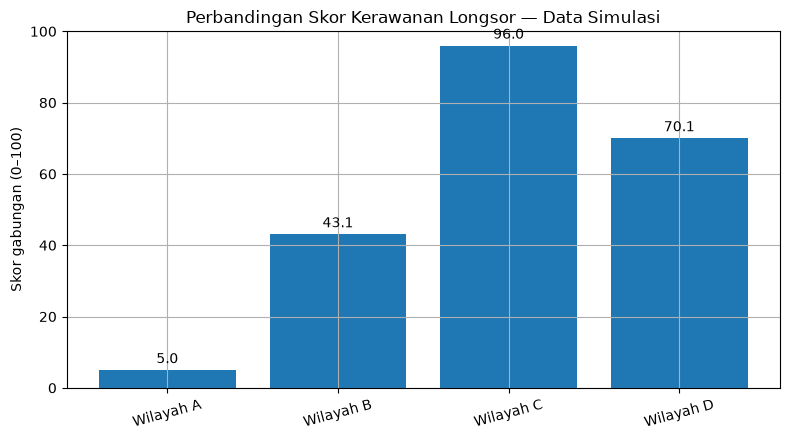

Unit dengan skor tertinggi: Wilayah C
Unit dengan skor terendah: Wilayah A


In [3]:
# METODE 1 — VISUALISASI SKOR
fig, ax = plt.subplots()
bars = ax.bar(longsor["Unit wilayah"], longsor["Skor gabungan"])
ax.set_title("Perbandingan Skor Kerawanan Longsor — Data Simulasi")
ax.set_ylabel("Skor gabungan (0–100)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=15)
for bar, score in zip(bars, longsor["Skor gabungan"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            f"{score:.1f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print("Unit dengan skor tertinggi:", longsor.loc[longsor["Skor gabungan"].idxmax(), "Unit wilayah"])
print("Unit dengan skor terendah:", longsor.loc[longsor["Skor gabungan"].idxmin(), "Unit wilayah"])

## Interpretasi hasil — WebGIS
Skor gabungan menunjukkan urutan relatif ant unit simulasi menurut bobot dan data yang ditentukan. Unit dengan skor tertinggi merupakan prioritas untuk ditinjau lebih lanjut dalam contoh ini; skor tersebut **tidak membuktikan** bahwa wilayah nyata pasti paling rawan longsor. Kelas sangat bergantung pada bobot, normalisasi, kualitas data, dan ambang kelas.

Untuk penerapan nyata, data DEM dapat digunakan untuk memperoleh kemiringan dan elevasi; data hujan perlu memiliki cakupan waktu dan spasial yang sesuai; penggunaan lahan dan geologi harus memiliki sumber serta tahun data yang jelas. Hasil perlu dibandingkan dengan titik kejadian longsor dan diuji sebelum dipublikasikan. WebGIS sebaiknya menyertakan legenda, sumber data, tanggal pembaruan, metode, dan peringatan bahwa peta bukan pengganti informasi resmi kebencanaan.

---

# 2. Pengukuran Topografi Menggunakan Theodolite

### R — Role
Berperan sebagai surveyor/geofisikawan yang mengolah pengukuran sudut dan jarak menjadi koordinat titik.

### T — Task
Menghitung koordinat horizontal dan elevasi relatif dari titik referensi, azimuth, jarak horizontal, dan beda tinggi.

### C — Context
Data topografi dapat mendukung pemetaan geologi, perencanaan survei, dan koreksi topografi pada metode geofisika. Dalam survei nyata, orientasi alat, tinggi alat (HI), tinggi target (HT), sudut vertikal, dan datum harus diketahui.

### I — Input
Notebook menggunakan titik referensi simulasi, azimuth, jarak horizontal, dan beda tinggi terkoreksi.

### C — Constraints
Tidak ada data theodolite asli pada berkas prompt. Karena itu angka berikut hanya contoh hitungan. Azimuth didefinisikan dari sumbu X positif berlawanan arah jarum jam agar rumus koordinat konsisten.

### O — Output
Tabel koordinat X-Y dan elevasi, sketsa posisi, serta profil elevasi.

### Q — Quality criteria
Satuan konsisten; definisi sudut dinyatakan; rumus koordinat transparan.

### V — Verification
Koordinat dihitung ulang langsung dari persamaan trigonometri, dan rentang elevasi ditampilkan.

## Metode
Dengan azimuth \(\theta\) diukur dari sumbu X positif:

\[
X = X_0 + D_h\cos(\theta),\quad
Y = Y_0 + D_h\sin(\theta)
\]

Elevasi contoh dihitung dari \(Z = Z_0 + \Delta h\), dengan \(\Delta h\) sebagai beda tinggi yang diasumsikan sudah direduksi dari pengamatan. Rumus ini tidak menggantikan reduksi sudut vertikal/tinggi alat dari catatan lapangan.

In [4]:
# METODE 2 — PENGOLAHAN KOORDINAT TITIK SIMULASI
x0, y0, z0 = 500.0, 1000.0, 100.0
topo = pd.DataFrame({
    "Titik": ["P1", "P2", "P3", "P4", "P5"],
    "Azimuth (derajat)": [0, 35, 80, 125, 210],
    "Jarak horizontal (m)": [20, 25, 18, 22, 16],
    "Beda tinggi (m)": [0.8, 1.4, -0.3, 2.0, -1.1]
})
theta = np.deg2rad(topo["Azimuth (derajat)"])
topo["X (m)"] = x0 + topo["Jarak horizontal (m)"] * np.cos(theta)
topo["Y (m)"] = y0 + topo["Jarak horizontal (m)"] * np.sin(theta)
topo["Elevasi (m)"] = z0 + topo["Beda tinggi (m)"]
display(topo.round(3))
print(f"Elevasi minimum: {topo['Elevasi (m)'].min():.2f} m")
print(f"Elevasi maksimum: {topo['Elevasi (m)'].max():.2f} m")

,Titik,Azimuth (derajat),Jarak horizontal (m),Beda tinggi (m),X (m),Y (m),Elevasi (m)
0,P1,0,20,0.8,520.000,1000.000,100.8
1,P2,35,25,1.4,520.479,1014.339,101.4
2,P3,80,18,-0.3,503.126,1017.727,99.7
3,P4,125,22,2.0,487.381,1018.021,102.0
4,P5,210,16,-1.1,486.144,992.000,98.9


Elevasi minimum: 98.90 m
Elevasi maksimum: 102.00 m


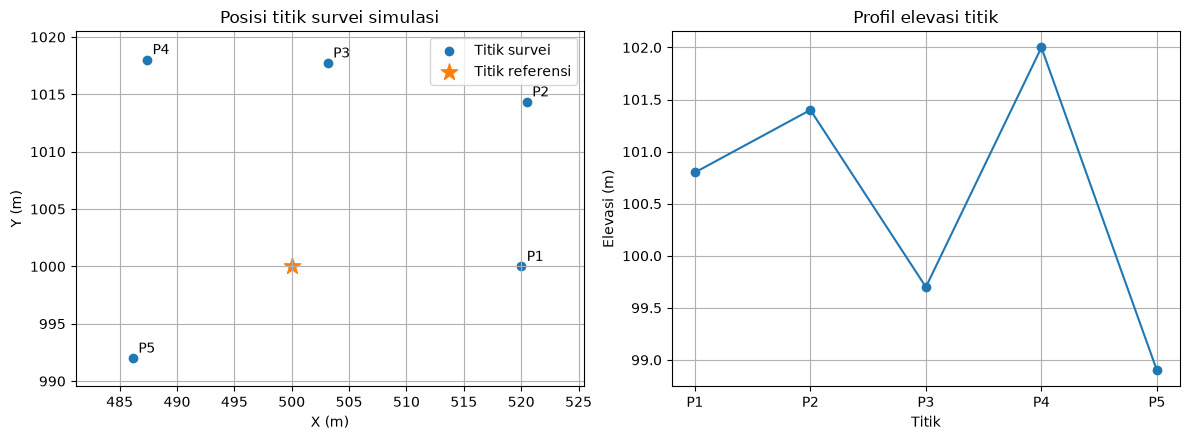

In [5]:
# METODE 2 — SKETSA POSISI DAN PROFIL ELEVASI
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(topo["X (m)"], topo["Y (m)"], label="Titik survei")
axes[0].scatter([x0], [y0], marker="*", s=150, label="Titik referensi")
for _, row in topo.iterrows():
    axes[0].annotate(row["Titik"], (row["X (m)"], row["Y (m)"]), xytext=(4, 4), textcoords="offset points")
axes[0].set_xlabel("X (m)"); axes[0].set_ylabel("Y (m)")
axes[0].set_title("Posisi titik survei simulasi"); axes[0].axis("equal"); axes[0].legend()

axes[1].plot(topo["Titik"], topo["Elevasi (m)"], marker="o")
axes[1].set_xlabel("Titik"); axes[1].set_ylabel("Elevasi (m)")
axes[1].set_title("Profil elevasi titik")
plt.tight_layout()
plt.show()

## Interpretasi hasil — Theodolite
Koordinat X dan Y menggambarkan posisi relatif titik terhadap referensi sesuai konvensi azimuth yang digunakan. Elevasi merupakan elevasi relatif terhadap datum contoh setelah menambahkan beda tinggi. Titik dengan beda tinggi negatif lebih rendah daripada datum awal, sedangkan beda tinggi positif lebih tinggi.

Pada survei nyata, ketelitian tidak dapat dinilai hanya dari tabel koordinat. Diperlukan informasi penutupan poligon, pengamatan backsight/foresight, HI dan HT, sudut vertikal, kalibrasi instrumen, sistem koordinat, serta kesalahan penutup. Nilai yang tidak tersedia pada prompt tidak boleh diisi dengan asumsi lalu dilaporkan sebagai pengukuran aktual.

---

# 3. Drone Mapping untuk Pemetaan Topografi

### R — Role
Berperan sebagai analis fotogrametri yang mengevaluasi kualitas produk pemetaan drone.

### T — Task
Mendemonstrasikan evaluasi akurasi horizontal dan vertikal dari residu checkpoint (CP), serta membedakan orthomosaic, DSM, dan DTM.

### C — Context
Foto udara bertampalan dapat diproses dengan fotogrametri untuk membentuk orthomosaic dan model permukaan. GCP membantu mengikat model ke koordinat, sedangkan CP independen digunakan untuk menguji akurasi.

### I — Input
Tidak tersedia foto drone, metadata penerbangan, GCP, atau CP aktual. Notebook memakai residu CP sintetis dalam meter.

### C — Constraints
Data simulasi bukan hasil pemrosesan drone. Tanpa foto, overlap, kamera, GCP/CP dan koordinat referensi, notebook tidak dapat menghasilkan orthomosaic atau DSM/DTM nyata.

### O — Output
Tabel residu, RMSE X/Y/Z, RMSE horizontal 2D, dan grafik residu.

### Q — Quality criteria
Rumus RMSE dinyatakan, satuan meter digunakan, dan akurasi horizontal dipisahkan dari vertikal.

### V — Verification
Perhitungan RMSE memakai akar dari rata-rata kuadrat residu; semua nilai berasal dari tabel yang sama.

## Metode
Untuk residu checkpoint \(e_i\), RMSE suatu komponen dihitung sebagai:

\[
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} e_i^2}
\]

RMSE horizontal 2D dihitung sebagai \(\sqrt{\frac{1}{n}\sum (dx_i^2+dy_i^2)}\). Evaluasi formal sebaiknya mengikuti standar yang sesuai dan memakai checkpoint independen yang tersebar merata di area pemetaan.

In [6]:
# METODE 3 — RESIDU CHECKPOINT SIMULASI
cp = pd.DataFrame({
    "Checkpoint": ["CP1", "CP2", "CP3", "CP4", "CP5", "CP6"],
    "dx (m)": [0.04, -0.06, 0.03, 0.08, -0.02, 0.01],
    "dy (m)": [-0.03, 0.02, 0.05, -0.04, 0.01, -0.02],
    "dz (m)": [0.07, -0.09, 0.05, 0.12, -0.04, 0.06]
})
rmse_x = np.sqrt(np.mean(cp["dx (m)"]**2))
rmse_y = np.sqrt(np.mean(cp["dy (m)"]**2))
rmse_z = np.sqrt(np.mean(cp["dz (m)"]**2))
rmse_h = np.sqrt(np.mean(cp["dx (m)"]**2 + cp["dy (m)"]**2))
metrics = pd.DataFrame({
    "Metrik": ["RMSE X", "RMSE Y", "RMSE horizontal 2D", "RMSE Z"],
    "Nilai (m)": [rmse_x, rmse_y, rmse_h, rmse_z]
})
display(cp)
display(metrics.round(4))

,Checkpoint,dx (m),dy (m),dz (m)
0,CP1,0.04,-0.03,0.07
1,CP2,-0.06,0.02,-0.09
2,CP3,0.03,0.05,0.05
3,CP4,0.08,-0.04,0.12
4,CP5,-0.02,0.01,-0.04
5,CP6,0.01,-0.02,0.06


,Metrik,Nilai (m)
0,RMSE X,0.046
1,RMSE Y,0.031
2,RMSE horizontal 2D,0.056
3,RMSE Z,0.076


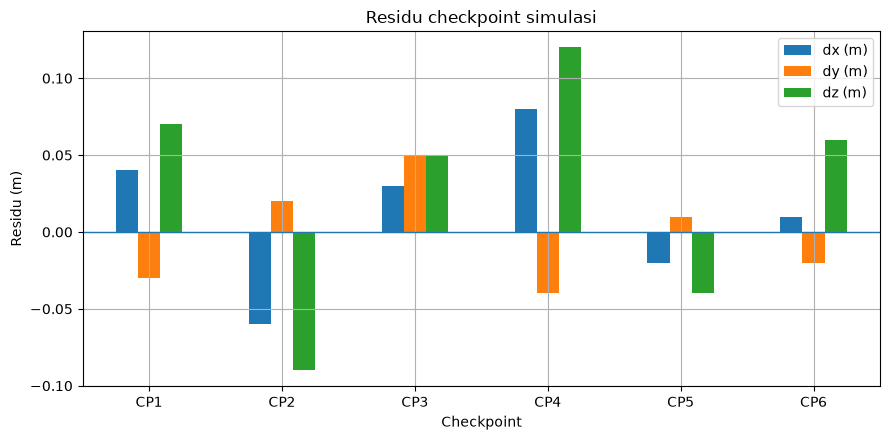

RMSE horizontal 2D: 0.056 m
RMSE vertikal Z: 0.076 m


In [7]:
# METODE 3 — VISUALISASI RESIDU
ax = cp.set_index("Checkpoint")[["dx (m)", "dy (m)", "dz (m)"]].plot(kind="bar", figsize=(9, 4.5))
ax.axhline(0, linewidth=1)
ax.set_title("Residu checkpoint simulasi")
ax.set_ylabel("Residu (m)")
ax.set_xlabel("Checkpoint")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("RMSE horizontal 2D:", f"{rmse_h:.3f} m")
print("RMSE vertikal Z:", f"{rmse_z:.3f} m")

## Interpretasi hasil — Drone mapping
RMSE horizontal dan vertikal merangkum besar residu checkpoint pada data contoh. Nilai RMSE yang lebih kecil menunjukkan residu lebih kecil pada sampel tersebut, tetapi tidak membuktikan akurasi keseluruhan produk drone jika checkpoint sedikit atau tidak tersebar merata.

Orthomosaic adalah citra yang telah dikoreksi secara geometrik; DSM merepresentasikan permukaan beserta objek di atasnya; DTM berupaya merepresentasikan permukaan tanah tanpa objek seperti vegetasi dan bangunan. Ketelitian produk dipengaruhi kualitas foto, overlap, geometri penerbangan, kalibrasi kamera, distribusi GCP/CP, dan pengaturan pemrosesan. Karena data foto tidak tersedia, produk raster aktual tidak dihasilkan di notebook ini.

---

# 4. Seismik Refraksi untuk Investigasi Bawah Permukaan

### R — Role
Berperan sebagai geofisikawan yang menganalisis first break seismik refraksi untuk memperkirakan kecepatan gelombang P dan model lapisan dangkal.

### T — Task
Membentuk kurva waktu–jarak, mengestimasi kecepatan dari kemiringan segmen, dan menghitung ketebalan lapisan atas dengan model dua lapisan ideal.

### C — Context
Pada model dua lapisan mendatar dengan lapisan bawah lebih cepat, gelombang langsung dan gelombang refraksi kritis memiliki tren waktu–jarak berbeda. Data lapangan memerlukan picking first break yang benar serta pemeriksaan forward/reverse shot.

### I — Input
Notebook membuat data waktu tiba sintetis dengan parameter model yang diketahui untuk menguji alur analisis.

### C — Constraints
Ini bukan data rekaman seismik aktual. Model mengasumsikan dua lapisan mendatar, kecepatan konstan per lapisan, dan lapisan kedua lebih cepat.

### O — Output
Kurva waktu–jarak, kecepatan estimasi, waktu intersep, dan estimasi ketebalan lapisan atas.

### Q — Quality criteria
Persamaan dan satuan konsisten; asumsi model disebutkan; interpretasi litologi tidak dipastikan hanya dari Vp.

### V — Verification
Kecepatan estimasi dibandingkan dengan nilai model sintetis yang dipakai untuk membentuk data.

## Teori singkat
Gelombang langsung memiliki hubungan \(t=x/V_1\). Untuk model dua lapisan ideal, cabang gelombang kepala dapat ditulis:

\[
t = t_i + \frac{x}{V_2},\qquad
t_i = \frac{2h\sqrt{V_2^2-V_1^2}}{V_1V_2}
\]

Dengan kemiringan kurva waktu–jarak \(m\), kecepatan diperkirakan dari \(V=1/m\). Persamaan intersep digunakan untuk mengestimasi ketebalan \(h\) dengan asumsi model ideal.

In [8]:
# METODE 4 — DATA WAKTU TIBA SINTETIS
rng = np.random.default_rng(7)
V1_true, V2_true, h_true = 500.0, 1800.0, 5.0  # m/s dan m
x = np.arange(5.0, 101.0, 5.0)
ti_true = 2*h_true*np.sqrt(V2_true**2 - V1_true**2)/(V1_true*V2_true)
t_direct = x / V1_true
t_head = ti_true + x / V2_true
# Pilih first arrival ideal, lalu tambahkan noise kecil simulasi
t_first = np.minimum(t_direct, t_head) + rng.normal(0, 0.0004, size=len(x))

seis = pd.DataFrame({
    "Jarak (m)": x,
    "Waktu langsung ideal (ms)": t_direct*1000,
    "Waktu refraksi ideal (ms)": t_head*1000,
    "First break simulasi (ms)": t_first*1000
})
display(seis.round(2))
print(f"Waktu intersep model sintetis = {ti_true*1000:.2f} ms")

,Jarak (m),Waktu langsung ideal (ms),Waktu refraksi ideal (ms),First break simulasi (ms)
0,5.0,10.0,21.99,10.00
1,10.0,20.0,24.77,20.12
2,15.0,30.0,27.55,27.44
3,20.0,40.0,30.32,29.97
4,25.0,50.0,33.10,32.92
5,30.0,60.0,35.88,35.48
6,35.0,70.0,38.66,38.68
7,40.0,80.0,41.44,41.97
8,45.0,90.0,44.21,44.02
9,50.0,100.0,46.99,46.74


Waktu intersep model sintetis = 19.21 ms


In [9]:
# METODE 4 — REGRESI DUA CABANG DAN ESTIMASI MODEL
# Crossover teoritis untuk menentukan cabang first arrival
x_cross = ti_true / (1/V1_true - 1/V2_true)
direct_mask = x < x_cross
refr_mask = x >= x_cross

m1, b1 = np.polyfit(x[direct_mask], t_first[direct_mask], 1)
m2, b2 = np.polyfit(x[refr_mask], t_first[refr_mask], 1)
V1_est = 1/m1
V2_est = 1/m2
ti_est = b2
h_est = ti_est * V1_est * V2_est / (2*np.sqrt(V2_est**2 - V1_est**2))

print(f"Vp lapisan 1 estimasi = {V1_est:.1f} m/s (model: {V1_true:.1f} m/s)")
print(f"Vp lapisan 2 estimasi = {V2_est:.1f} m/s (model: {V2_true:.1f} m/s)")
print(f"Ketebalan lapisan atas estimasi = {h_est:.2f} m (model: {h_true:.2f} m)")
print(f"Intersep estimasi = {ti_est*1000:.2f} ms")

Vp lapisan 1 estimasi = 494.1 m/s (model: 500.0 m/s)
Vp lapisan 2 estimasi = 1810.9 m/s (model: 1800.0 m/s)
Ketebalan lapisan atas estimasi = 4.95 m (model: 5.00 m)
Intersep estimasi = 19.26 ms


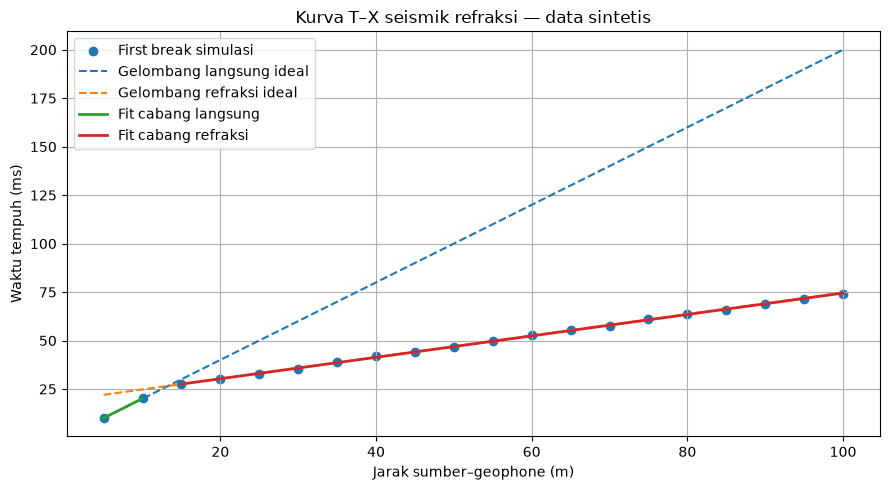

In [10]:
# METODE 4 — VISUALISASI KURVA T-X
plt.figure(figsize=(9, 5))
plt.scatter(x, t_first*1000, label="First break simulasi")
plt.plot(x, t_direct*1000, "--", label="Gelombang langsung ideal")
plt.plot(x, t_head*1000, "--", label="Gelombang refraksi ideal")
plt.plot(x[direct_mask], (m1*x[direct_mask]+b1)*1000, linewidth=2, label="Fit cabang langsung")
plt.plot(x[refr_mask], (m2*x[refr_mask]+b2)*1000, linewidth=2, label="Fit cabang refraksi")
plt.xlabel("Jarak sumber–geophone (m)")
plt.ylabel("Waktu tempuh (ms)")
plt.title("Kurva T–X seismik refraksi — data sintetis")
plt.legend()
plt.tight_layout()
plt.show()

## Interpretasi hasil — Seismik refraksi
Kurva waktu–jarak menunjukkan bahwa gelombang langsung dan refraksi memiliki kemiringan berbeda. Kemiringan yang lebih landai berkaitan dengan kecepatan yang lebih tinggi. Dalam model simulasi, lapisan kedua dibuat lebih cepat daripada lapisan pertama, sehingga gelombang refraksi dapat menjadi first arrival pada jarak yang lebih jauh.

Estimasi kecepatan dan ketebalan harus dibandingkan dengan nilai model yang dipakai untuk menghasilkan data sintetis. Selisih dapat muncul akibat noise dan pemilihan titik untuk regresi. Data nyata dapat mengandung lapisan miring, variasi lateral, lapisan tersembunyi, atau kecepatan yang tidak meningkat dengan kedalaman; kondisi tersebut dapat membuat model dua lapisan tidak memadai. Nilai Vp saja tidak cukup untuk memastikan litologi.

---

# 5. Geolistrik Resistivitas untuk Identifikasi Bawah Permukaan

### R — Role
Berperan sebagai geofisikawan yang mengolah data geolistrik resistivitas dan menafsirkan variasi resistivitas bawah permukaan.

### T — Task
Menghitung resistivitas semu dari arus, beda potensial, dan faktor geometri konfigurasi Wenner serta menggambarkan perubahan nilainya terhadap spasi elektroda.

### C — Context
Survei resistivitas menginjeksikan arus melalui elektroda arus dan mengukur beda potensial melalui elektroda potensial. Resistivitas semu merepresentasikan respons gabungan bawah permukaan dan bukan nilai resistivitas satu lapisan secara langsung.

### I — Input
Data arus, beda potensial, dan spasi elektroda sintetis. Tidak tersedia data inversi atau topografi lapangan.

### C — Constraints
Nilai adalah simulasi. Tidak boleh menyimpulkan jenis batuan hanya dari satu rentang resistivitas karena nilai dipengaruhi kadar air, porositas, lempung, temperatur, dan salinitas.

### O — Output
Tabel faktor geometri dan resistivitas semu serta grafik resistivitas semu terhadap spasi.

### Q — Quality criteria
Rumus faktor geometri sesuai konfigurasi Wenner; satuan ditulis; perbedaan resistivitas semu dan model hasil inversi dijelaskan.

### V — Verification
Nilai dihitung ulang dari rumus \(\rho_a=K\Delta V/I\), dan hasil dicek bernilai positif untuk arus serta beda potensial positif.

## Teori singkat
Untuk konfigurasi Wenner dengan jarak antar elektroda berurutan sebesar \(a\), faktor geometri ideal adalah:

\[
K=2\pi a
\]

Resistivitas semu dihitung menggunakan:

\[
\rho_a = K\frac{\Delta V}{I}
\]

dengan \(\Delta V\) beda potensial dan \(I\) arus. Perhitungan ini menghasilkan resistivitas semu, bukan penampang resistivitas 2D hasil inversi.

In [11]:
# METODE 5 — DATA GEOLISTRIK SINTETIS DAN RESISTIVITAS SEMU
geo = pd.DataFrame({
    "Spasi Wenner a (m)": [1, 2, 3, 4, 5, 6, 7],
    "Arus I (A)": [0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10],
    "Beda potensial dV (V)": [0.80, 0.55, 0.42, 0.34, 0.28, 0.24, 0.21]
})
geo["K (m)"] = 2*np.pi*geo["Spasi Wenner a (m)"]
geo["Resistivitas semu (ohm m)"] = geo["K (m)"] * geo["Beda potensial dV (V)"] / geo["Arus I (A)"]
assert (geo["Arus I (A)"] > 0).all()
assert (geo["Beda potensial dV (V)"] > 0).all()
display(geo.round(3))
print("Rentang resistivitas semu:",
      f"{geo['Resistivitas semu (ohm m)'].min():.2f}–{geo['Resistivitas semu (ohm m)'].max():.2f} ohm m")

,Spasi Wenner a (m),Arus I (A),Beda potensial dV (V),K (m),Resistivitas semu (ohm m)
0,1,0.1,0.80,6.283,50.265
1,2,0.1,0.55,12.566,69.115
2,3,0.1,0.42,18.850,79.168
3,4,0.1,0.34,25.133,85.451
4,5,0.1,0.28,31.416,87.965
5,6,0.1,0.24,37.699,90.478
6,7,0.1,0.21,43.982,92.363


Rentang resistivitas semu: 50.27–92.36 ohm m


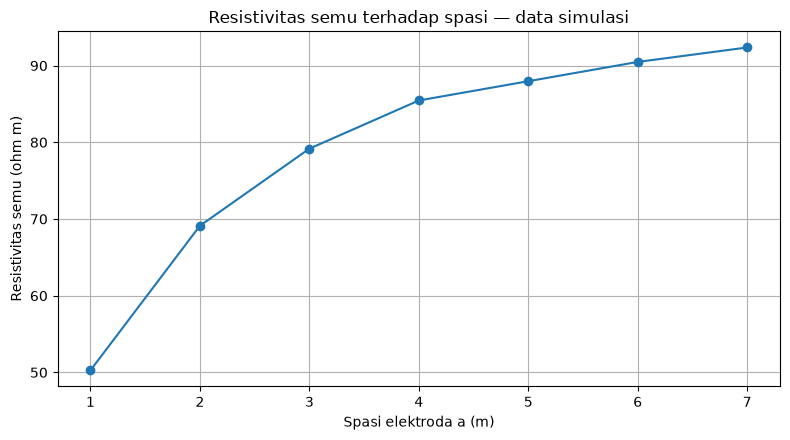

In [12]:
# METODE 5 — VISUALISASI RESISTIVITAS SEMU
plt.figure(figsize=(8, 4.5))
plt.plot(geo["Spasi Wenner a (m)"], geo["Resistivitas semu (ohm m)"], marker="o")
plt.xlabel("Spasi elektroda a (m)")
plt.ylabel("Resistivitas semu (ohm m)")
plt.title("Resistivitas semu terhadap spasi — data simulasi")
plt.tight_layout()
plt.show()

## Interpretasi hasil — Geolistrik
Resistivitas semu berubah terhadap spasi elektroda pada data simulasi. Perubahan ini menunjukkan bahwa pengukuran dengan konfigurasi berbeda merespons volume bawah permukaan yang berbeda. Spasi yang lebih besar umumnya meningkatkan sensitivitas pada bagian yang lebih dalam, tetapi kedalaman investigasi tidak sama secara langsung dengan nilai spasi elektroda.

Interpretasi geologi tidak dapat dilakukan secara pasti hanya dari grafik resistivitas semu. Penampang bawah permukaan umumnya diperoleh melalui inversi 2D/3D dan perlu dievaluasi bersama RMS error, topografi, konfigurasi elektroda, kualitas kontak, serta informasi geologi. Zona resistivitas rendah dapat berkaitan dengan material lempungan atau jenuh air, tetapi konteks geologi setempat tetap menentukan interpretasi.

---

# Kesimpulan Umum

Lima eksekusi ini menunjukkan bahwa prompt geofisika yang terstruktur dapat diterjemahkan menjadi alur analisis yang lebih sistematis: menetapkan tujuan, menyatakan input, memilih metode, menghasilkan tabel/grafik, lalu menafsirkan hasil dengan memperhatikan keterbatasan.

1. **WebGIS:** skoring berbobot dapat menyusun prioritas relatif, tetapi memerlukan data spasial dan validasi kejadian nyata.
2. **Theodolite:** koordinat dan elevasi dapat dihitung dari pengukuran sudut/jarak dengan datum dan konvensi yang jelas.
3. **Drone mapping:** RMSE checkpoint membantu merangkum residu, tetapi tidak menggantikan pemeriksaan produk fotogrametri dan distribusi titik kontrol.
4. **Seismik refraksi:** kemiringan kurva T–X berkaitan dengan kecepatan gelombang; estimasi ketebalan bergantung pada asumsi model.
5. **Geolistrik:** resistivitas semu dihitung dari arus, beda potensial, dan faktor geometri; interpretasi bawah permukaan memerlukan inversi dan informasi pendukung.

**Batasan utama:** seluruh angka dan grafik yang dibuat dengan Python adalah data sintetis. Untuk laporan ilmiah atau keputusan lapangan, ganti data simulasi dengan data aktual, dokumentasikan sumbernya, dan lakukan validasi yang sesuai.